In [3]:
import numpy as np
import sys
sys.path.append('/home/samanwaya.mukherjee/gwfit/gwfit')
sys.path.append('/home/samanwaya/gwfit/gwfit')
import imrphenomd_horizon as phenom_wf
import matplotlib.pyplot as plt

from pycbc.waveform import get_fd_waveform
from pycbc.filter import match
from pycbc.psd import aLIGOZeroDetHighPower

import time as tt

/home/samanwaya.mukherjee/.conda/envs/lalsuite-esigma/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1298: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


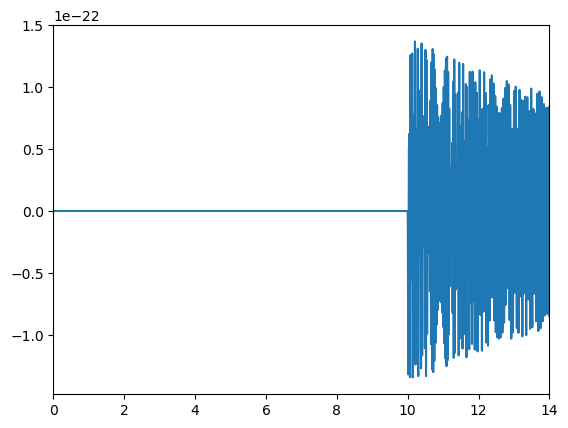

time taken to generate PhenomD_Horizon = 2.910 secs
time taken to generate PhenomD = 0.036 secs


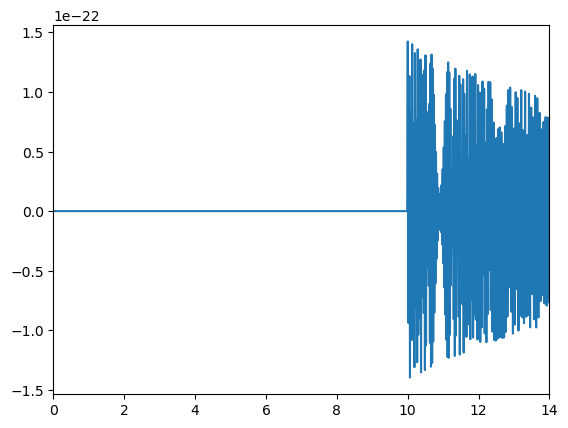

The mismatch is: 0.85%


In [5]:
Ms=30
q=7
m1=Ms*q/(1+q)
m2=Ms/(1+q)
chi1=-0.8
chi2=-0.8
f_low=10
delta_f=2**-6
# %matplotlib notebook

start1=tt.time()
hp, hc = phenom_wf.get_imrphenomd_horizon_fd(m1=m1,m2=m2,chi1=chi1,chi2=chi2,f_lower=f_low,delta_f=delta_f,phase_corr=1,amp_corr=1)
end1=tt.time()

time1=end1-start1

plt.plot(hp.sample_frequencies,hp)
plt.xlim(0,f_low+4)
plt.show()

start2=tt.time()
sp, sc = get_fd_waveform(approximant="IMRPhenomD",
                         mass1=m1,
                         mass2=m2,
                         spin1z=chi1,
                         spin2z=chi2,
                         f_lower=f_low,
                         distance=200,
                         delta_f=delta_f)
end2=tt.time()
time2=end2-start2
print(f'time taken to generate PhenomD_Horizon = {time1:.3f} secs')
print(f'time taken to generate PhenomD = {time2:.3f} secs')

plt.plot(sp.sample_frequencies,sp)
plt.xlim(0,f_low+4)
plt.show()

# Resize the waveforms to the same length
tlen = max(len(sp), len(hp))
sp.resize(tlen)
hp.resize(tlen)

# # Generate the aLIGO ZDHP PSD
# delta_f = 1.0 / sp.duration
# flen = tlen//2 + 1
psd = aLIGOZeroDetHighPower(len(sp), delta_f, f_low)

# Note: This takes a while the first time as an FFT plan is generated
# subsequent calls are much faster.
m, i = match(hp, sp, psd=psd, low_frequency_cutoff=f_low)
print(f'The mismatch is: {(1-m)*100:.2f}%')

/home/samanwaya.mukherjee/gwfit/gwfit/useful_relations.py:277: RuntimeWarning: overflow encountered in exp
  if t[i]<t4 and t[i]>t3: w.append(1./(np.exp(z(t[i]))+1))
/home/samanwaya.mukherjee/.conda/envs/lalsuite-esigma/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1298: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


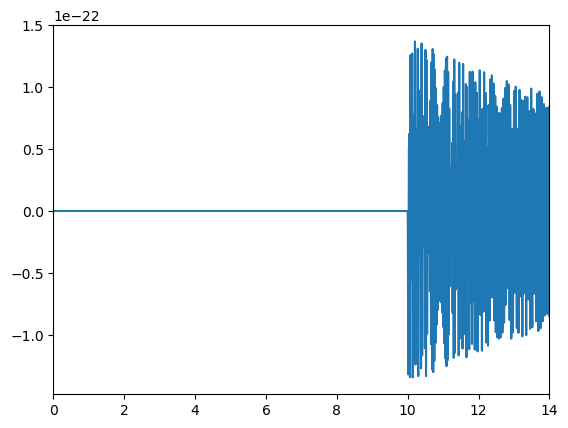

time taken to generate PhenomD_Horizon = 5.502 secs
time taken to generate PhenomD = 0.040 secs


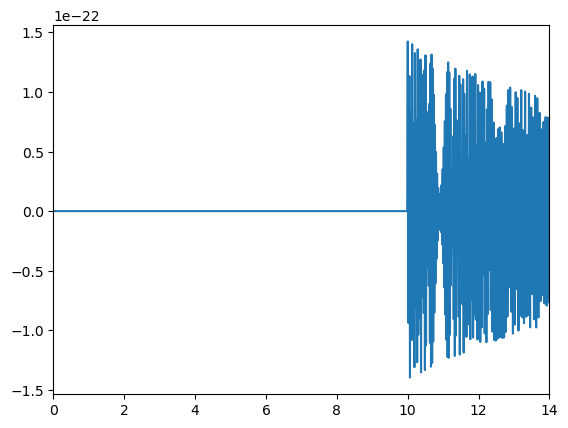

The mismatch is: 0.85%


In [6]:
Ms=30
q=7
m1=Ms*q/(1+q)
m2=Ms/(1+q)
chi1=-0.8
chi2=-0.8
f_low=10
delta_f=2**-6
# %matplotlib notebook

start1=tt.time()
hp, hc = phenom_wf.get_imrphenomd_heated_fd(m1=m1,m2=m2,chi1=chi1,chi2=chi2,f_lower=f_low,delta_f=delta_f,phase_corr=1,amp_corr=1)
end1=tt.time()

time1=end1-start1

plt.plot(hp.sample_frequencies,hp)
plt.xlim(0,f_low+4)
plt.show()

start2=tt.time()
sp, sc = get_fd_waveform(approximant="IMRPhenomD",
                         mass1=m1,
                         mass2=m2,
                         spin1z=chi1,
                         spin2z=chi2,
                         f_lower=f_low,
                         distance=200,
                         delta_f=delta_f)
end2=tt.time()
time2=end2-start2
print(f'time taken to generate PhenomD_Horizon = {time1:.3f} secs')
print(f'time taken to generate PhenomD = {time2:.3f} secs')

plt.plot(sp.sample_frequencies,sp)
plt.xlim(0,f_low+4)
plt.show()

# Resize the waveforms to the same length
tlen = max(len(sp), len(hp))
sp.resize(tlen)
hp.resize(tlen)

# # Generate the aLIGO ZDHP PSD
# delta_f = 1.0 / sp.duration
# flen = tlen//2 + 1
psd = aLIGOZeroDetHighPower(len(sp), delta_f, f_low)

# Note: This takes a while the first time as an FFT plan is generated
# subsequent calls are much faster.
m, i = match(hp, sp, psd=psd, low_frequency_cutoff=f_low)
print(f'The mismatch is: {(1-m)*100:.2f}%')